# BTP — executed pipeline notebook

Exact record of the final run (10 seeds, protocols P1/P2/P3) that produced the results in `results/` and `figures/`. Code cells are unchanged from the executed notebook; only markdown headings were added and Jupyter-widget progress bars were removed from the stored outputs. The same pipeline is available as scripts in `src/`.

## Step 0 — Environment: mount Google Drive and create the project folders

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
ROOT = '/content/drive/MyDrive/btp'
for d in ['data','src','results','figures','notebooks','report','presentation','literature']:
    os.makedirs(f'{ROOT}/{d}', exist_ok=True)
os.chdir(ROOT)
print(os.listdir(ROOT))

Mounted at /content/drive
['data', 'src', 'results', 'figures', 'notebooks', 'report', 'presentation', 'literature', 'requirements.txt']


## Step 1 — Data loading, label-alignment check and timing audit (NIFTY / SPY)

Builds the clean table, recovers the daily price series from the context windows, verifies that the label is the **next** trading day's close-to-close return, and asserts that no input window reaches the day being predicted.

In [2]:
# =====================================================================
# BTP Step 1: load NIFTY, build clean table, lagged windows, timing audit
# Run in Google Colab, cell by cell (cells are separated by "# %%").
# Colab setup (run once in its own cell):  !pip -q install datasets pyarrow
# =====================================================================

# %% Cell 0: imports and config
import re, io, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

LOOKBACK = 10                      # previous trading days fed to the LSTM
OUT = Path("/content/drive/MyDrive/btp/data"); OUT.mkdir(parents=True, exist_ok=True)
FIG = Path("/content/drive/MyDrive/btp/figures"); FIG.mkdir(parents=True, exist_ok=True)

HEADER = ("date,open,high,low,close,adj_close,volume,pct_change,macd,boll_ub,boll_lb,"
          "rsi_30,cci_30,dx_30,close_30_sma,close_60_sma")
# Model inputs: adj_close dropped (duplicate of close). pct_change inside the context
# is the PREVIOUS days' return, which is allowed.
FEATS = ["open","high","low","close","volume","pct_change","macd","boll_ub","boll_lb",
         "rsi_30","cci_30","dx_30","close_30_sma","close_60_sma"]
SPLITS = ["train", "valid", "test"]
DATE_ROW = re.compile(r"^\s*(\d{4}-\d{2}-\d{2}),")

# %% Cell 1: load and INSPECT the raw format (paste this cell's output back to your assistant)
from datasets import load_dataset
ds = load_dataset("raeidsaqur/NIFTY")      # if it fails, try revision="refs/convert/parquet"
print(ds)
r = ds["train"][0]
print("keys:", list(r.keys()))
print("context col:", repr(r["context"][:200]))
print("PROMPT (first 1800 chars):\n", repr(r["conversations"][0]["value"][:1800]))
print("NEWS (first 500 chars):\n", repr(r["news"][:500]))
print("label / pct_change:", r["label"], r["pct_change"])

# %% Cell 2: parsing helpers
def get_prompt(r):
    return next(c["value"] for c in r["conversations"] if c["role"] == "user")

def parse_context(prompt, header=HEADER):
    """Pull the dated market rows out of the prompt text."""
    rows = [l.strip() for l in prompt.splitlines() if DATE_ROW.match(l)]
    if not rows:
        return None
    df_temp = pd.read_csv(io.StringIO(header + "\n" + "\n".join(rows)))
    df_temp["date"] = pd.to_datetime(df_temp["date"])
    return df_temp.sort_values("date").reset_index(drop=True)

def label_from_pct(p, thr=0.005):
    return "Rise" if p > thr else ("Fall" if p < -thr else "Neutral")

# %% Cell 3: build the clean table
def build(ds):
    recs, ctxs, bad = [], [], []
    for split in SPLITS:
        for r in ds[split]:
            try:
                c = parse_context(get_prompt(r), HEADER)
            except Exception as e:
                c, err = None, str(e)
            if c is None or len(c) == 0:
                bad.append(r["id"]); continue
            heads = [h.strip() for h in r["news"].split("\n") if h.strip()]
            recs.append(dict(id=r["id"], date=pd.to_datetime(r["date"]), split=split,
                             label=r["label"], pct_change=float(r["pct_change"]),
                             news="\n".join(heads), n_headlines=len(heads),
                             ctx_len=len(c), ctx_first=c["date"].iloc[0], ctx_last=c["date"].iloc[-1]))
            ctxs.append(c)
    if bad:
        raise RuntimeError(f"Could not parse market context for {len(bad)} rows, e.g. {bad[:5]}. "
                           "Paste the Cell 1 output to your assistant so the parser can be fixed.")
    df_temp = pd.DataFrame(recs)
    return df_temp, ctxs

df, ctxs = build(ds)
print(df.shape); print(df.groupby("split").date.agg(["min", "max", "count"]))
print("mean headlines per day:", df.n_headlines.mean(),
      "(about 1 means the headline separator is not a newline: check Cell 1)")

# %% Cell 4: timing audit (the leakage guard)
# 4a. every input window must end strictly before the target date
assert (df.ctx_last < df.date).all(), "LEAK: some context windows include the target day"
print("OK: latest input date is strictly before target date for all", len(df), "rows")
print("context lengths:", df.ctx_len.value_counts().to_dict())
print("gap (calendar days) between last input and target:", (df.date - df.ctx_last).dt.days.value_counts().sort_index().to_dict())
for i in np.random.default_rng(0).choice(len(df), 5, replace=False):
    print(f"target {df.date[i].date()}  | last input {df.ctx_last[i].date()}  | label {df.label[i]}  | pct {df["pct_change"][i]:+.4f}")

# 4b. label rule check (card says Neutral if |change| < 0.50%)
mism = (df["pct_change"].map(label_from_pct) != df.label)
print("label vs +/-0.5% rule mismatches:", int(mism.sum()), "of", len(df))

# %% Cell 5: daily series rebuilt from the context windows + contiguity check
daily = (pd.concat(ctxs).drop_duplicates("date").sort_values("date").reset_index(drop=True))
print("unique trading days recovered from contexts:", len(daily), "|", daily.date.min().date(), "to", daily.date.max().date())

# approximate expected trading days: business days minus US federal holidays (approximation only!)
from pandas.tseries.holiday import USFederalHolidayCalendar
hol = USFederalHolidayCalendar().holidays(daily.date.min(), daily.date.max())
expected = pd.bdate_range(daily.date.min(), daily.date.max()).difference(hol)
missing = expected.difference(pd.DatetimeIndex(daily.date))
print(f"expected (approx) trading days: {len(expected)} | recovered: {len(daily)} | missing: {len(missing)}")
print("sample missing days:", [d.date().isoformat() for d in missing[:15]])

# how gappy are the TARGET dates themselves?
td = df.sort_values("date").date
print("target rows:", len(td), "vs approx trading days in the same range:",
      len(pd.bdate_range(td.min(), td.max()).difference(USFederalHolidayCalendar().holidays(td.min(), td.max()))))
gaps = pd.Series(np.busday_count(td.values[:-1].astype("datetime64[D]"), td.values[1:].astype("datetime64[D]")))
print("target-date gaps in business days (1 = consecutive):", gaps.value_counts().sort_index().to_dict())

# does the target's pct_change agree with the daily series (same return definition)?
m = df.merge(daily[["date", "pct_change"]].rename(columns={"pct_change": "pct_ctx"}), on="date", how="inner")
if len(m):
    print(f"target pct_change vs context pct_change on {len(m)} overlapping dates: "
          f"share within 1e-3 = {(np.abs(m["pct_change"] - m["pct_ctx"]) < 1e-3).mean():.3f}")

# %% Cell 5b: DIAGNOSTIC - what does the label's pct_change actually measure? (paste output back)
allc = pd.concat(ctxs)
print("max disagreement in close across duplicate context rows:", allc.groupby("date")["close"].agg(lambda s: s.max() - s.min()).max())

d = daily.set_index("date")
d["ret_cc"] = d["close"].pct_change()          # close-to-close, from our recovered series
d["ret_oc"] = d["close"] / d["open"] - 1       # open-to-close
cmp = pd.DataFrame({"target": df.set_index("date")["pct_change"]})
cmp["cc_same_day"] = d["ret_cc"].reindex(cmp.index)
cmp["cc_next_day"] = d["ret_cc"].shift(-1).reindex(cmp.index)
cmp["cc_prev_day"] = d["ret_cc"].shift(1).reindex(cmp.index)
cmp["oc_same_day"] = d["ret_oc"].reindex(cmp.index)
cmp["ctx_pct_same_day"] = d["pct_change"].reindex(cmp.index)
print(cmp.corr()["target"].round(3))
for c in cmp.columns[1:]:
    print(f"{c:18s} share within 1e-3 of target: {(np.abs(cmp["target"] - cmp[c]) < 1e-3).mean():.3f}")
print(cmp.describe().loc[["mean", "std", "min", "max"]].round(4))
print(cmp.head(6).round(4))
print("label-rule mismatches:"); print(df.loc[mism, ["date", "label", "pct_change"]])


# %% Cell 6: lagged windows built from the recovered DAILY series (contexts only hold 4-8 rows)
# FINDING from Cell 5b: the label pct_change for date t equals close(t+1)/close(t) - 1, i.e. the NEXT trading day's move.
# So close(t) is known before the move being predicted, and a window ending at t is legitimate.
# (The benchmark's own context stops at t-1, so it leaves day t's market data out. LAG=1 reproduces that convention.)
LAG = 0          # 0: window ends at date t (default) | 1: window ends at t-1 (robustness check)
REGIME_WINDOW = 20
daily = daily.sort_values("date").reset_index(drop=True)
daily["ret"] = daily["close"].pct_change()     # our own close-to-close return, used as the return feature
FEATS2 = [f if f != "pct_change" else "ret" for f in FEATS]

dts = df["date"].values
nxt = daily["date"].searchsorted(dts, side="right")      # first daily row AFTER t = day the label's move ends on
pos = nxt - LAG                                          # window = daily.iloc[pos-LOOKBACK : pos]

# alignment check: label == close-to-close return of the next trading day
okn = nxt < len(daily)
share = (np.abs(daily["ret"].to_numpy()[nxt[okn]] - df["pct_change"].to_numpy()[okn]) < 1e-3).mean()
print(f"label equals next-trading-day close-to-close return on {okn.sum()} rows: share = {share:.4f}")
assert share > 0.99, "label alignment differs from what the pipeline assumes"

keep = pos >= REGIME_WINDOW + 1                          # same rows for every model (enough history for 20-day regime features)
print(f"dropped {int((~keep).sum())} early rows without 20 days of history:", df.loc[~keep, "date"].dt.date.astype(str).tolist())
df = df[keep].reset_index(drop=True); pos = pos[keep]; nxt = nxt[keep]

X = np.stack([daily.iloc[p - LOOKBACK:p][FEATS2].to_numpy(dtype=float) for p in pos])
last_in = pd.DatetimeIndex([daily["date"].iloc[p - 1] for p in pos]); first_in = pd.DatetimeIndex([daily["date"].iloc[p - LOOKBACK] for p in pos])
tgt = pd.DatetimeIndex(df["date"])
assert (last_in <= tgt).all() and (LAG == 0 or (last_in < tgt).all()), "LEAK: window extends past the allowed date"
has_end = nxt < len(daily)                               # label end-day row exists in our series (not for the very last dates)
lab_end = daily["date"].to_numpy()[np.minimum(nxt, len(daily) - 1)]
assert (last_in.values[has_end] < lab_end[has_end]).all(), "LEAK: window reaches the day the label move ends on"
print("X shape:", X.shape, "| NaNs:", int(np.isnan(X).sum()), "| max calendar span of a 10-row window (days):", int((last_in - first_in).days.max()))
print("rows per split after dropping:", df.split.value_counts().to_dict())
y = df.label.map({"Fall": 0, "Neutral": 1, "Rise": 2}).to_numpy()

df.to_parquet(OUT / "clean.parquet"); daily.to_parquet(OUT / "daily_series.parquet")
np.save(OUT / "X_price_windows.npy", X); np.save(OUT / "y.npy", y)
print("saved to", OUT)


DatasetDict({
    train: Dataset({
        features: ['id', 'date', 'context', 'news', 'conversations', 'label', 'pct_change'],
        num_rows: 1477
    })
    test: Dataset({
        features: ['id', 'date', 'context', 'news', 'conversations', 'label', 'pct_change'],
        num_rows: 317
    })
    valid: Dataset({
        features: ['id', 'date', 'context', 'news', 'conversations', 'label', 'pct_change'],
        num_rows: 317
    })
})
keys: ['id', 'date', 'context', 'news', 'conversations', 'label', 'pct_change']
context col: 'date,open,high,low,close,adj_close,volume,pct_change,macd,boll_ub,boll_lb,rsi_30,cci_30,dx_30,close_30_sma,close_60_sma'
PROMPT (first 1800 chars):
 "Project the $SPY index's movement by assessing market data and news headlines from 2010-01-06. Offer a reply as 'Rise', 'Fall', or 'Neutral', along with the predicted percentage change in a newline. Conclude with 'Neutral' if the envisaged modification is under 0.50%.\nContext:date,open,high,low,close,adj_clo

## Step 1 (cont.) — Exploratory data analysis: class balance, headline volume, price history

label   Fall  Neutral   Rise
split                       
test   0.230    0.451  0.319
train  0.205    0.535  0.260
valid  0.167    0.596  0.237
             mean   min     max
split                          
test    26.179811   7.0    46.0
train  277.358413  11.0  1627.0
valid   53.735016  18.0    93.0
missing values per column:
 Series([], dtype: int64)


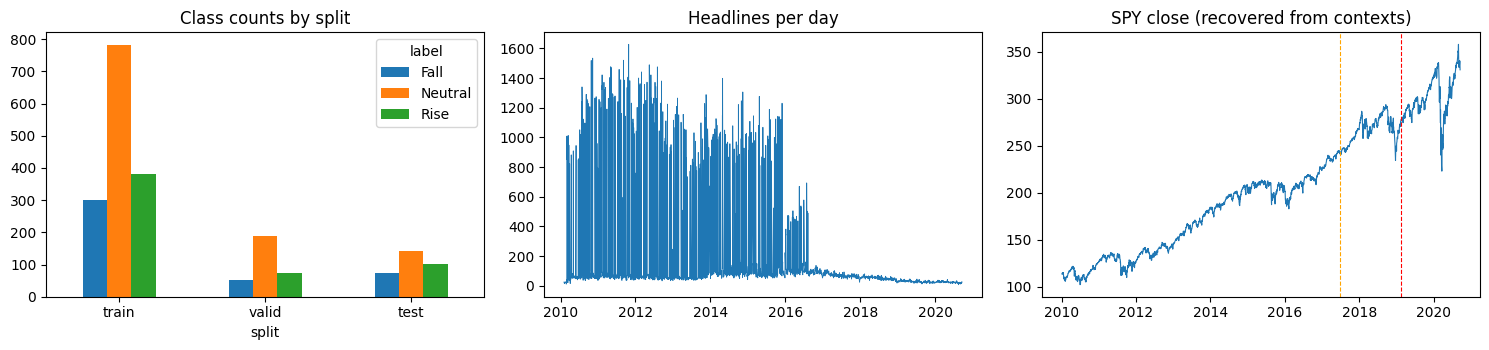

In [3]:


# %% Cell 7: EDA (class balance, news volume, price history)
print(pd.crosstab(df.split, df.label, normalize="index").round(3))
print(df.groupby("split").n_headlines.describe()[["mean", "min", "max"]])
print("missing values per column:\n", df.isna().sum()[lambda s: s > 0])

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
pd.crosstab(df.split, df.label).loc[SPLITS].plot.bar(ax=ax[0], rot=0); ax[0].set_title("Class counts by split")
ax[1].plot(df.date, df.n_headlines, lw=.6); ax[1].set_title("Headlines per day")
ax[2].plot(daily.date, daily.close, lw=.8); ax[2].set_title("SPY close (recovered from contexts)")
for s, c in zip(["valid", "test"], ["orange", "red"]):
    ax[2].axvline(df[df.split == s].date.min(), color=c, ls="--", lw=.8)
plt.tight_layout(); plt.savefig(FIG / "eda_overview.png", dpi=200); plt.show()

## Step 2 — Market regimes

3-state KMeans on 20-day return and log 20-day volatility. The strict protocol (P3) fits the scaler and clusters on training rows only; P1/P2 fit on all rows.

(2096, 10) (2695, 17)
NaNs in regime features: 0
share of rows with the same regime under train-only vs all-data fit: 0.9356
{'test': 0.9495, 'train': 0.9227, 'valid': 0.9811}
Regime stats on TRAIN rows (P3 fit):
             n  mean_ret20  mean_vol20  mean_next_day_ret   share
Low-vol   700      0.0185      0.0055            -0.0000  0.4788
Mid-vol   411      0.0319      0.0103             0.0009  0.2811
High-vol  351     -0.0363      0.0126             0.0010  0.2401

Regime share by split (P3 fit):
 regime_p3  High-vol  Low-vol  Mid-vol
split                                
test          0.249    0.394    0.356
train         0.240    0.479    0.281
valid         0.243    0.640    0.117

Label mix within each regime (P3 fit), all splits:
 label       Fall  Neutral   Rise
regime_p3                       
High-vol   0.306    0.288  0.406
Low-vol    0.164    0.642  0.194
Mid-vol    0.182    0.549  0.269
Transition matrix (daily, P3 model):
           Low-vol  Mid-vol  High-vol
Low-vol  

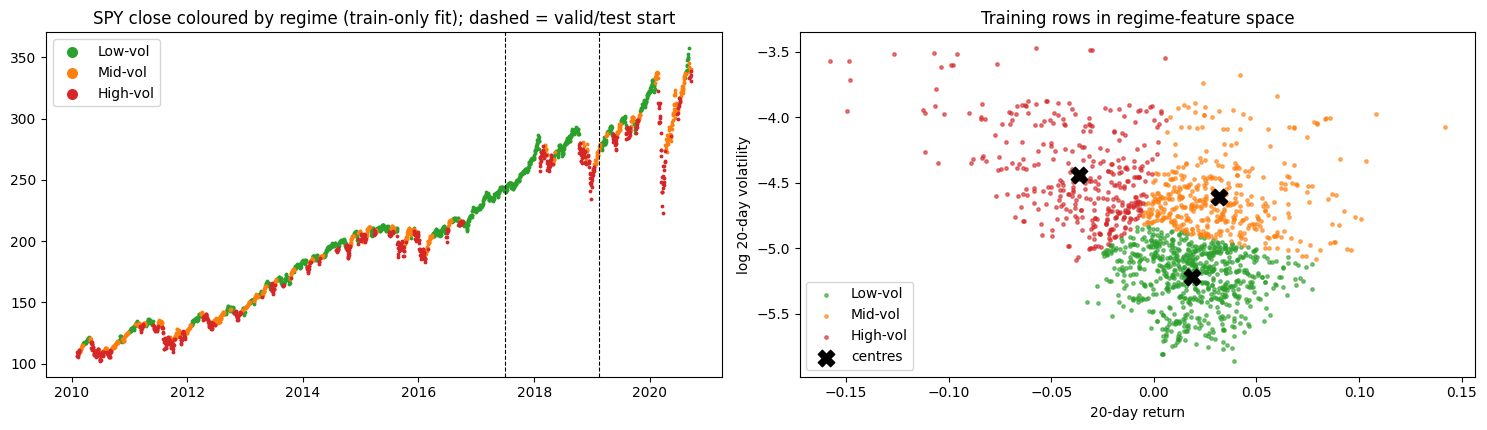

saved regimes.parquet, stats, transition matrix, models


In [4]:
# =====================================================================
# BTP Step 2: market regimes (3-state KMeans on rolling return + volatility)
# Run in Colab after Step 1 has saved clean.parquet and daily_series.parquet.
# Cells are separated by "# %%".
# =====================================================================

# %% Cell 0: imports and config
import itertools, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

ROOT = Path("/content/drive/MyDrive/btp"); DATA = ROOT / "data"; FIG = ROOT / "figures"; RES = ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
LAG = 0          # MUST match LAG in Step 1 Cell 6 (0 = window ends at target date t)
W = 20           # rolling window (trading days) for regime features
K = 3            # number of regimes
KM_SEED = 0      # fixed: the regime labelling is part of data preparation, not a per-model seed
NAMES = ["Low-vol", "Mid-vol", "High-vol"]   # named by volatility rank only, never by guesswork
COLORS = ["tab:green", "tab:orange", "tab:red"]

# %% Cell 1: load Step 1 outputs
df = pd.read_parquet(DATA / "clean.parquet").reset_index(drop=True)
daily = pd.read_parquet(DATA / "daily_series.parquet").sort_values("date").reset_index(drop=True)
print(df.shape, daily.shape)

# %% Cell 2: regime features (each uses only prices up to its own date)
daily["ret"] = daily["close"].pct_change()
daily["ret20"] = daily["close"] / daily["close"].shift(W) - 1          # 20-day return
daily["vol20"] = daily["ret"].rolling(W).std()                         # 20-day volatility of daily returns
daily["lvol20"] = np.log(daily["vol20"])                               # log: volatility is right-skewed, so clusters are not dominated by crashes
FEAT = ["ret20", "lvol20"]

# last daily row each target row is allowed to use (same rule as the price windows in Step 1)
idx = daily["date"].searchsorted(df["date"].values, side="right") - 1 - LAG
assert (idx >= 0).all()
assert (daily["date"].to_numpy()[idx] <= df["date"].to_numpy()).all(), "LEAK: regime feature uses a future day"
for c in ["ret20", "vol20", "lvol20"]:
    df[c] = daily[c].to_numpy()[idx]
print("NaNs in regime features:", int(df[FEAT].isna().sum().sum()))

# %% Cell 3: the fit function -- takes the rows to fit on, which is what the leakage audit varies
def fit_regimes(X, seed=KM_SEED):
    sc = StandardScaler().fit(X)
    km = KMeans(n_clusters=K, n_init=10, random_state=seed).fit(sc.transform(X))
    centers = sc.inverse_transform(km.cluster_centers_)
    order = np.argsort(centers[:, 1])                  # rank clusters by mean log-volatility
    remap = np.empty(K, dtype=int); remap[order] = np.arange(K)
    return dict(sc=sc, km=km, remap=remap)

def assign_regimes(model, X):
    return model["remap"][model["km"].predict(model["sc"].transform(X))]

is_train = (df["split"] == "train").to_numpy()
X_all = df[FEAT].to_numpy()
m_p3 = fit_regimes(X_all[is_train])      # P3 (strict): fit on training rows only
m_p12 = fit_regimes(X_all)               # P1/P2: fit on all rows (deliberately leaky)
df["regime_p3"] = assign_regimes(m_p3, X_all)
df["regime_all"] = assign_regimes(m_p12, X_all)

agree = (df["regime_p3"] == df["regime_all"])
print("share of rows with the same regime under train-only vs all-data fit:", round(agree.mean(), 4))
print(agree.groupby(df["split"]).mean().round(4).to_dict())

# %% Cell 4: inspect the regimes (paste this output back)
def regime_stats(d, col):
    g = d.groupby(col).agg(n=("ret20", "size"), mean_ret20=("ret20", "mean"), mean_vol20=("vol20", "mean"),
                           mean_next_day_ret=("pct_change", "mean"))
    g["share"] = g["n"] / g["n"].sum()
    g.index = [NAMES[i] for i in g.index]
    return g.round(4)

stats_train = regime_stats(df[is_train], "regime_p3")
print("Regime stats on TRAIN rows (P3 fit):\n", stats_train)
print("\nRegime share by split (P3 fit):\n", pd.crosstab(df["split"], df["regime_p3"].map(dict(enumerate(NAMES))), normalize="index").round(3))
print("\nLabel mix within each regime (P3 fit), all splits:\n",
      pd.crosstab(df["regime_p3"].map(dict(enumerate(NAMES))), df["label"], normalize="index").round(3))

# %% Cell 5: persistence -- transition matrix and run lengths on the DAILY series (P3 model)
ok = daily[FEAT].notna().all(axis=1).to_numpy()
daily["regime_p3"] = np.nan
daily.loc[ok, "regime_p3"] = assign_regimes(m_p3, daily.loc[ok, FEAT].to_numpy())
seq = daily["regime_p3"].dropna().astype(int).to_numpy()
T = pd.crosstab(pd.Series(seq[:-1], name="from"), pd.Series(seq[1:], name="to"), normalize="index").round(3)
T.index = [NAMES[i] for i in T.index]; T.columns = [NAMES[i] for i in T.columns]
print("Transition matrix (daily, P3 model):\n", T)
runs = pd.DataFrame([(NAMES[k], len(list(g))) for k, g in itertools.groupby(seq)], columns=["regime", "run_len"])
print("\nRun length in trading days:\n", runs.groupby("regime")["run_len"].agg(["count", "mean", "median", "max"]).round(1))

# %% Cell 6: figures
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
d = daily.dropna(subset=["regime_p3"])
for r in range(K):
    s = d[d["regime_p3"] == r]
    ax[0].scatter(s["date"], s["close"], s=3, color=COLORS[r], label=NAMES[r])
for sp, c in [("valid", "k"), ("test", "k")]:
    ax[0].axvline(df.loc[df["split"] == sp, "date"].min(), color=c, ls="--", lw=.8)
ax[0].set_title("SPY close coloured by regime (train-only fit); dashed = valid/test start")
ax[0].legend(markerscale=4)

tr = df[is_train]
for r in range(K):
    s = tr[tr["regime_p3"] == r]
    ax[1].scatter(s["ret20"], s["lvol20"], s=6, color=COLORS[r], alpha=.6, label=NAMES[r])
cen = m_p3["sc"].inverse_transform(m_p3["km"].cluster_centers_)
ax[1].scatter(cen[:, 0], cen[:, 1], marker="X", s=140, c="k", label="centres")
ax[1].set_xlabel("20-day return"); ax[1].set_ylabel("log 20-day volatility"); ax[1].set_title("Training rows in regime-feature space")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "regimes_overview.png", dpi=200); plt.show()

# %% Cell 7: save
df[["id", "ret20", "vol20", "lvol20", "regime_p3", "regime_all"]].to_parquet(DATA / "regimes.parquet")
stats_train.to_csv(RES / "regime_stats_train.csv"); T.to_csv(RES / "regime_transition_matrix.csv")
joblib.dump(m_p3, DATA / "regime_model_p3.joblib"); joblib.dump(m_p12, DATA / "regime_model_p12.joblib")
print("saved regimes.parquet, stats, transition matrix, models")

## Step 3 — Frozen FinBERT embeddings (run once)

Up to 50 randomly sampled headlines per day (fixed seed) are embedded with `ProsusAI/finbert`; mean-pooled to one 768-d vector and three sentiment probabilities per day.

In [5]:
# =====================================================================
# BTP Step 3: frozen FinBERT embeddings of each day's headlines (run ONCE, then never again)
# Colab: switch runtime to a T4 GPU first (Runtime > Change runtime type), then re-run the
# Drive-mount and pip-install cells from Step 0 (the runtime restarts).
# Cells are separated by "# %%".
# =====================================================================

# %% Cell 0: imports and config
import time
import numpy as np, pandas as pd, torch
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/btp"); DATA = ROOT / "data"
CAP = 50              # max headlines embedded per day (random sample, fixed seed)
SAMPLE_SEED = 1234
MAX_LEN = 64          # tokens per headline
BS = 256              # batch size (lower to 64 if the GPU runs out of memory)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "(CPU works but is slow; consider CAP = 20)" if device == "cpu" else "")

# %% Cell 1: choose the headlines to embed
df = pd.read_parquet(DATA / "clean.parquet").reset_index(drop=True)   # same row order as the price windows
rng = np.random.default_rng(SAMPLE_SEED)
rows, texts = [], []
n_used = np.zeros(len(df), dtype=int)
for i, txt in enumerate(df["news"]):
    hs = [h.strip() for h in txt.split("\n") if h.strip()]
    if len(hs) > CAP:                                   # cap very heavy news days; sample is random, not "first 50"
        keep = np.sort(rng.choice(len(hs), CAP, replace=False)); hs = [hs[j] for j in keep]
    n_used[i] = len(hs); rows += [i] * len(hs); texts += hs
rows = np.array(rows)
print(len(texts), "headlines to embed | days with 0 headlines:", int((n_used == 0).sum()))
print("mean headlines used per day, by split:", pd.Series(n_used).groupby(df["split"].values).mean().round(1).to_dict())

# %% Cell 2: load frozen FinBERT
from transformers import AutoTokenizer, AutoModelForSequenceClassification
tok = AutoTokenizer.from_pretrained("ProsusAI/finbert")
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").to(device).eval()
print("label order:", model.config.id2label)

# %% Cell 3: embed (one pass gives both a 768-d embedding and 3 sentiment probabilities)
@torch.no_grad()
def encode(texts):
    order = np.argsort([len(t) for t in texts])           # similar lengths together = less padding
    emb = np.zeros((len(texts), 768), np.float32); sent = np.zeros((len(texts), 3), np.float32)
    for s in range(0, len(texts), BS):
        ids = order[s:s + BS]
        b = tok([texts[j] for j in ids], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(device)
        with torch.autocast(device_type=device, dtype=torch.float16 if device == "cuda" else torch.bfloat16, enabled=(device == "cuda")):
            out = model(**b, output_hidden_states=True)
        h = out.hidden_states[-1].float(); m = b["attention_mask"].unsqueeze(-1).float()
        emb[ids] = ((h * m).sum(1) / m.sum(1)).cpu().numpy()             # mean over tokens (padding masked)
        sent[ids] = torch.softmax(out.logits.float(), -1).cpu().numpy()
    return emb, sent

t0 = time.time()
emb_h, sent_h = encode(texts)
print(f"embedded {len(texts)} headlines in {time.time() - t0:.0f}s")

# %% Cell 4: average headlines per day, save
N = len(df)
news_emb = pd.DataFrame(emb_h).groupby(rows).mean().reindex(range(N)).fillna(0).to_numpy(np.float32)
news_sent = pd.DataFrame(sent_h).groupby(rows).mean().reindex(range(N)).fillna(0).to_numpy(np.float32)
assert news_emb.shape == (N, 768) and news_sent.shape == (N, 3)

np.save(DATA / "news_emb.npy", news_emb); np.save(DATA / "news_sent.npy", news_sent)
pd.DataFrame({"id": df["id"], "n_headlines": df["n_headlines"], "n_used": n_used}).to_parquet(DATA / "news_meta.parquet")
pd.Series(model.config.id2label).to_json(DATA / "finbert_label_order.json")
print("saved news_emb.npy", news_emb.shape, "| news_sent.npy", news_sent.shape)

# %% Cell 5: sanity checks (paste this output back)
print("NaNs:", int(np.isnan(news_emb).sum()), "| mean L2 norm:", float(np.linalg.norm(news_emb, axis=1).mean().round(2)))
lab = {v.lower(): k for k, v in model.config.id2label.items()}
senti = pd.Series(news_sent[:, lab["positive"]] - news_sent[:, lab["negative"]], index=df["date"].values)
print("mean (positive - negative) FinBERT sentiment by split:", senti.groupby(df["split"].values).mean().round(3).to_dict())
ym = senti.index.strftime("%Y-%m").to_numpy(); is_mar20 = ym == "2020-03"; is_test = (df["split"] == "test").to_numpy()
print("Mar 2020 mean sentiment:", round(senti[is_mar20].mean(), 3), "| rest of test:", round(senti[is_test & ~is_mar20].mean(), 3))
# do two different days look different? (cosine similarity of consecutive days vs random pairs)
cs = lambda a, b: float((a * b).sum(1).mean() / (np.linalg.norm(a, axis=1).mean() * np.linalg.norm(b, axis=1).mean()))
perm = np.random.default_rng(0).permutation(N)
print("avg cosine, consecutive days:", round(cs(news_emb[:-1], news_emb[1:]), 3), "| random pairs:", round(cs(news_emb, news_emb[perm]), 3))

device: cuda 
94652 headlines to embed | days with 0 headlines: 0
mean headlines used per day, by split: {'test': 26.2, 'train': 49.0, 'valid': 46.4}


label order: {0: 'positive', 1: 'negative', 2: 'neutral'}
embedded 94652 headlines in 33s
saved news_emb.npy (2096, 768) | news_sent.npy (2096, 3)
NaNs: 0 | mean L2 norm: 7.929999828338623
mean (positive - negative) FinBERT sentiment by split: {'test': -0.18400000035762787, 'train': -0.06800000369548798, 'valid': -0.0949999988079071}
Mar 2020 mean sentiment: -0.319 | rest of test: -0.176
avg cosine, consecutive days: 0.963 | random pairs: 0.951


## Step 4 — Models M0–M6 and the training / evaluation harness

All hyper-parameters are frozen (no tuning on the test set). M0r (random guess) and M6 (price + sentiment) were added after the pilot run; see the transparency note in the README.

In [13]:
# =====================================================================
# BTP Step 4: models M0-M5 and the training/evaluation harness (run P3 first)
# Cells are separated by "# %%". Runs fine on CPU.
#   M0 majority | M0r uniform random | M1 price LSTM | M2 price+news | M3 price+news+regime | M4 news only | M5 regime only
#   M6 price + FinBERT sentiment (3 numbers) -- low-capacity news channel, ADDED after seeing that the 768-d news input overfits
# =====================================================================

# %% Cell 0: imports and FROZEN hyperparameters (do not tune on test)
import copy, time, warnings
import numpy as np, pandas as pd, torch
import torch.nn as nn
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score
warnings.filterwarnings("ignore", category=UserWarning)

ROOT = Path("/content/drive/MyDrive/btp"); DATA = ROOT / "data"; RES = ROOT / "results"; RES.mkdir(exist_ok=True)
SEEDS = list(range(10))
LOOKBACK, LAG = 10, 0                      # LAG must match Step 1 / Step 2
H, DROPOUT, NEWS_OUT, REG_EMB = 64, 0.2, 64, 8
LR, WD, BATCH, MAX_EPOCHS, PATIENCE = 1e-3, 1e-4, 64, 50, 8
CLIP = 5.0                                 # standardised inputs are clipped to +/-5 sd (COVID-era extremes)
SPLITS = ["train", "valid", "test"]

# %% Cell 1: load everything and build SCALE-FREE price features
df = pd.read_parquet(DATA / "clean.parquet").reset_index(drop=True)
daily = pd.read_parquet(DATA / "daily_series.parquet").sort_values("date").reset_index(drop=True)
reg = pd.read_parquet(DATA / "regimes.parquet").set_index("id").loc[df["id"]].reset_index()
news_emb = np.load(DATA / "news_emb.npy"); news_sent = np.load(DATA / "news_sent.npy"); meta = pd.read_parquet(DATA / "news_meta.parquet")
assert len(news_emb) == len(df) == len(news_sent) and (meta["id"].values == df["id"].values).all(), "news rows not aligned with clean table"
y = np.load(DATA / "y.npy")
assert (y == df["label"].map({"Fall": 0, "Neutral": 1, "Rise": 2}).to_numpy()).all()

# Raw price levels (open/high/low/close, Bollinger bands, SMAs) drift from ~100 to ~340 over the sample, so test-period
# inputs would sit far outside the training range. We therefore use scale-free versions: returns, ratios, bounded indicators.
d = daily; f = pd.DataFrame({"date": d["date"]})
f["ret"] = d["close"].pct_change()
f["oc"] = d["close"] / d["open"] - 1
f["hl"] = (d["high"] - d["low"]) / d["close"]
lv = np.log(d["volume"].replace(0, np.nan)); f["lvol_rel"] = lv - lv.rolling(20, min_periods=5).mean()
f["macd_n"] = d["macd"] / d["close"]
f["rsi"] = d["rsi_30"] / 100; f["cci"] = d["cci_30"] / 100; f["dx"] = d["dx_30"] / 100
f["bollpos"] = (d["close"] - d["boll_lb"]) / (d["boll_ub"] - d["boll_lb"])
f["bollw"] = (d["boll_ub"] - d["boll_lb"]) / d["close"]
f["c_sma30"] = d["close"] / d["close_30_sma"] - 1; f["c_sma60"] = d["close"] / d["close_60_sma"] - 1
FEAT = [c for c in f.columns if c != "date"]
F = f[FEAT].replace([np.inf, -np.inf], np.nan).to_numpy(float)

idx = daily["date"].searchsorted(df["date"].values, side="right") - 1 - LAG        # last day each window may use
assert (daily["date"].to_numpy()[idx] <= df["date"].to_numpy()).all(), "LEAK"
X = np.stack([F[i - LOOKBACK + 1:i + 1] for i in idx])
bad = np.isnan(X).any(axis=(0, 1))
assert not bad.any(), f"NaNs in features: {[c for c, b in zip(FEAT, bad) if b]}"
X_old = np.load(DATA / "X_price_windows.npy")                                       # Step 1 windows: same rows, raw features
assert np.allclose(X[:, :, 0], X_old[:, :, 5], atol=1e-6), "window rows differ from Step 1"
print("X", X.shape, "| features:", FEAT)
print("class counts (all rows):", np.bincount(y).tolist(), "| regimes available:", [c for c in reg.columns if c.startswith("regime")])

# %% Cell 2: protocols (the thing the leakage audit varies)
def get_split(protocol, seed):
    if protocol in ("P2", "P3"):                       # official chronological split
        return df["split"].to_numpy()
    rng = np.random.default_rng(1000 + seed)           # P1: random partition, same sizes (deliberately invalid)
    perm = rng.permutation(len(df)); n_tr = int((df["split"] == "train").sum()); n_va = int((df["split"] == "valid").sum())
    sp = np.empty(len(df), dtype=object)
    sp[perm[:n_tr]] = "train"; sp[perm[n_tr:n_tr + n_va]] = "valid"; sp[perm[n_tr + n_va:]] = "test"
    return sp

def prepare(protocol, seed):
    sp = get_split(protocol, seed)
    fit = (sp == "train") if protocol == "P3" else np.ones(len(sp), bool)   # P3: fit scalers on train only; P1/P2: on everything
    flat = X[fit].reshape(-1, X.shape[-1]); mu, sd = flat.mean(0), flat.std(0) + 1e-8
    Xs = np.clip((X - mu) / sd, -CLIP, CLIP).astype(np.float32)
    nm, ns = news_emb[fit].mean(0), news_emb[fit].std(0) + 1e-8
    Ns = np.clip((news_emb - nm) / ns, -CLIP, CLIP).astype(np.float32)
    sm, sdv = news_sent[fit].mean(0), news_sent[fit].std(0) + 1e-8
    Ss = np.clip((news_sent - sm) / sdv, -CLIP, CLIP).astype(np.float32)
    R = reg["regime_p3" if protocol == "P3" else "regime_all"].to_numpy().astype(np.int64)
    return sp, Xs, Ns, Ss, R

# %% Cell 3: models and training
MODELS = {"M1": (1, 0, 0), "M2": (1, 1, 0), "M3": (1, 1, 1), "M4": (0, 1, 0), "M5": (0, 0, 1), "M6": (1, 1, 0)}   # (price, news, regime)
NEWS_SRC = {"M6": "sent"}                                       # every other news model uses the 768-d embedding

class Net(nn.Module):
    def __init__(self, use_p, use_n, use_r, nfeat, ndim):
        super().__init__(); self.use_p, self.use_n, self.use_r = use_p, use_n, use_r; d = 0
        if use_p: self.lstm = nn.LSTM(nfeat, H, batch_first=True); d += H
        if use_n: self.news = nn.Sequential(nn.Linear(ndim, NEWS_OUT), nn.ReLU(), nn.Dropout(DROPOUT)); d += NEWS_OUT
        if use_r: self.emb = nn.Embedding(3, REG_EMB); d += REG_EMB
        self.drop = nn.Dropout(DROPOUT)
        self.head = nn.Sequential(nn.Linear(d, 64), nn.ReLU(), nn.Dropout(DROPOUT), nn.Linear(64, 3))
    def forward(self, x, n, r):
        parts = []
        if self.use_p: _, (h, _) = self.lstm(x); parts.append(self.drop(h[-1]))
        if self.use_n: parts.append(self.news(n))
        if self.use_r: parts.append(self.emb(r))
        return self.head(torch.cat(parts, 1))

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s)

def score(yt, yp):
    return dict(accuracy=accuracy_score(yt, yp), macro_f1=f1_score(yt, yp, average="macro", labels=[0, 1, 2], zero_division=0),
                balanced_acc=balanced_accuracy_score(yt, yp))

def run(model_id, protocol, seed):
    set_seed(seed); sp, Xs, Ns, Ss, R = prepare(protocol, seed)
    ix = {s: np.where(sp == s)[0] for s in SPLITS}; ytr = y[ix["train"]]
    if model_id == "M0":                                              # majority class of the training partition
        proba = np.zeros((len(y), 3), np.float32); proba[:, np.bincount(ytr, minlength=3).argmax()] = 1.0
    elif model_id == "M0r":                                           # uniform random guesses: the Macro-F1 floor for a balanced guesser
        proba = np.eye(3, dtype=np.float32)[np.random.default_rng(seed).integers(0, 3, len(y))]
    else:
        Nin = Ss if NEWS_SRC.get(model_id, "emb") == "sent" else Ns
        T = torch.as_tensor; xt, nt, rt, yt = T(Xs), T(Nin), T(R), T(y)
        cw = torch.tensor(len(ytr) / (3 * np.maximum(np.bincount(ytr, minlength=3), 1)), dtype=torch.float32)
        net = Net(*MODELS[model_id], Xs.shape[-1], Nin.shape[1]); opt = torch.optim.Adam(net.parameters(), lr=LR, weight_decay=WD)
        lossf = nn.CrossEntropyLoss(weight=cw); rng = np.random.default_rng(seed)
        best_f1, best_state, bad = -1.0, None, 0
        for ep in range(MAX_EPOCHS):
            net.train(); perm = rng.permutation(ix["train"])
            for i in range(0, len(perm), BATCH):
                b = T(perm[i:i + BATCH]); opt.zero_grad(); lossf(net(xt[b], nt[b], rt[b]), yt[b]).backward(); opt.step()
            net.eval(); v = T(ix["valid"])
            with torch.no_grad(): pv = net(xt[v], nt[v], rt[v]).argmax(1).numpy()
            f1 = f1_score(y[ix["valid"]], pv, average="macro", labels=[0, 1, 2], zero_division=0)   # early stopping on VALID only
            if f1 > best_f1: best_f1, best_state, bad = f1, copy.deepcopy(net.state_dict()), 0
            else:
                bad += 1
                if bad >= PATIENCE: break
        net.load_state_dict(best_state); net.eval()
        with torch.no_grad(): proba = torch.softmax(net(xt, nt, rt), 1).numpy()
    pred = proba.argmax(1)
    mrows = [dict(protocol=protocol, model=model_id, seed=seed, eval_split=s, n=len(ix[s]), **score(y[ix[s]], pred[ix[s]])) for s in SPLITS]
    prow = pd.DataFrame(dict(protocol=protocol, model=model_id, seed=seed, id=df["id"], date=df["date"], part=sp, y_true=y, y_pred=pred,
                             p_fall=proba[:, 0], p_neutral=proba[:, 1], p_rise=proba[:, 2], regime_used=R, regime_p3=reg["regime_p3"].to_numpy()))
    return mrows, prow

# %% Cell 4: run a grid and summarise
def run_grid(protocols, models=("M0", "M0r", "M1", "M2", "M3", "M4", "M5", "M6"), seeds=SEEDS):
    mrows, preds, t0 = [], [], time.time()
    for p in protocols:
        for m in models:
            for s in seeds:
                r, pr = run(m, p, s); mrows += r; preds.append(pr)
                te = [x for x in r if x["eval_split"] == "test"][0]
                print(f"{p} {m} seed{s}: test macro-F1 {te['macro_f1']:.3f} acc {te['accuracy']:.3f}  ({time.time() - t0:.0f}s)")
    tag = "_".join(protocols); M = pd.DataFrame(mrows); P = pd.concat(preds, ignore_index=True)
    M.to_csv(RES / f"metrics_{tag}.csv", index=False); P.to_parquet(RES / f"predictions_{tag}.parquet")
    return M, P

def summarize(M, protocol, split="test"):
    t = M[(M.protocol == protocol) & (M.eval_split == split)]
    g = t.groupby("model")[["macro_f1", "accuracy", "balanced_acc"]].agg(["mean", "std"]).round(3)
    return g


X (2096, 10, 12) | features: ['ret', 'oc', 'hl', 'lvol_rel', 'macd_n', 'rsi', 'cci', 'dx', 'bollpos', 'bollw', 'c_sma30', 'c_sma60']
class counts (all rows): [426, 1114, 556] | regimes available: ['regime_p3', 'regime_all']


## Steps 4–5 — Run all protocols (P1, P2, P3) × 10 seeds, then summarise test / validation / train

In [14]:
M_all, P_all = run_grid(["P1", "P2", "P3"])
for p in ["P3", "P2", "P1"]:
    print(p, "TEST\n", summarize(M_all, p, "test"))
print("P3 VALID\n", summarize(M_all, "P3", "valid")); print("P3 TRAIN\n", summarize(M_all, "P3", "train"))

P1 M0 seed0: test macro-F1 0.223 acc 0.502  (0s)
P1 M0 seed1: test macro-F1 0.230 acc 0.527  (0s)
P1 M0 seed2: test macro-F1 0.234 acc 0.543  (0s)
P1 M0 seed3: test macro-F1 0.224 acc 0.505  (0s)
P1 M0 seed4: test macro-F1 0.232 acc 0.533  (0s)
P1 M0 seed5: test macro-F1 0.222 acc 0.498  (0s)
P1 M0 seed6: test macro-F1 0.225 acc 0.508  (0s)
P1 M0 seed7: test macro-F1 0.234 acc 0.543  (0s)
P1 M0 seed8: test macro-F1 0.239 acc 0.558  (0s)
P1 M0 seed9: test macro-F1 0.222 acc 0.498  (1s)
P1 M0r seed0: test macro-F1 0.285 acc 0.303  (1s)
P1 M0r seed1: test macro-F1 0.314 acc 0.325  (1s)
P1 M0r seed2: test macro-F1 0.292 acc 0.309  (1s)
P1 M0r seed3: test macro-F1 0.315 acc 0.322  (1s)
P1 M0r seed4: test macro-F1 0.321 acc 0.331  (1s)
P1 M0r seed5: test macro-F1 0.306 acc 0.319  (1s)
P1 M0r seed6: test macro-F1 0.346 acc 0.356  (1s)
P1 M0r seed7: test macro-F1 0.315 acc 0.350  (1s)
P1 M0r seed8: test macro-F1 0.327 acc 0.344  (1s)
P1 M0r seed9: test macro-F1 0.328 acc 0.334  (1s)
P1 M1 seed

## Steps 5–7 — Analysis setup (helpers, metric function, load predictions)

In [15]:
# =====================================================================
# BTP Steps 5-7: protocol audit, news value by regime, stress-window case study, figures
# Needs results/predictions_P1_P2_P3.parquet and metrics_P1_P2_P3.csv from step4_models.py
# (run that with SEEDS = list(range(10)) first). Cells are separated by "# %%".
# =====================================================================

# %% Cell 0: imports, config, helpers
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/btp"); RES = ROOT / "results"; FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
STRESS = ("2020-02-01", "2020-04-30")          # stress-period case study window (by target date)
NBOOT = 1000
REG_NAMES = ["Low-vol", "Mid-vol", "High-vol"]
NAME = {"M0": "Majority", "M0r": "Random guess", "M1": "Price", "M2": "Price+News(emb)", "M3": "Price+News+Regime",
        "M4": "News only", "M5": "Regime only", "M6": "Price+Sentiment"}

def f1m(y, p):                                   # fast macro-F1 over classes 0,1,2 (class with no support and no predictions scores 0)
    cm = np.bincount(y * 3 + p, minlength=9).reshape(3, 3); tp = np.diag(cm).astype(float)
    den = cm.sum(0) + cm.sum(1)
    return float(np.mean(np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)))

P = pd.read_parquet(RES / "predictions_P1_P2_P3.parquet"); M = pd.read_csv(RES / "metrics_P1_P2_P3.csv")
T = M[M.eval_split == "test"]
print("seeds per cell:", T.groupby(["protocol", "model"]).seed.nunique().unique().tolist())

seeds per cell: [10]


## Step 5 — Evaluation-protocol audit (RQ1): Macro-F1 by protocol and the optimistic performance gap

TEST Macro-F1 by protocol (mean/std over seeds):
            mean                  std              
protocol     P1     P2     P3     P1     P2     P3
model                                             
M0        0.228  0.207  0.207  0.006  0.000  0.000
M0r       0.315  0.333  0.333  0.018  0.020  0.020
M1        0.438  0.460  0.466  0.034  0.036  0.036
M2        0.423  0.428  0.416  0.014  0.025  0.023
M3        0.421  0.441  0.433  0.021  0.020  0.025
M4        0.363  0.369  0.382  0.010  0.040  0.037
M5        0.400  0.382  0.354  0.022  0.030  0.019
M6        0.431  0.448  0.482  0.035  0.051  0.038

Optimistic performance gap (positive = looser protocol scores higher):
    model      gap    est     lo     hi
0     M1  P1 - P3 -0.028 -0.055  0.001
1     M1  P2 - P3 -0.005 -0.034  0.023
2     M2  P1 - P3  0.006 -0.010  0.022
3     M2  P2 - P3  0.012 -0.008  0.031
4     M3  P1 - P3 -0.012 -0.030  0.008
5     M3  P2 - P3  0.008 -0.010  0.028
6     M4  P1 - P3 -0.019 -0.040  0.004
7   

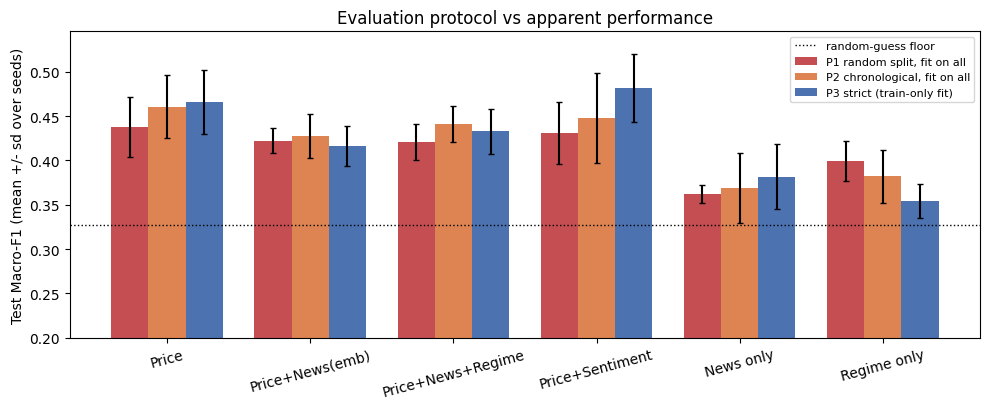

In [16]:


# %% Cell 1: RQ1 -- evaluation-protocol audit (seed-level; CI = bootstrap over seeds)
tab = T.pivot_table(index="model", columns="protocol", values="macro_f1", aggfunc=["mean", "std"]).round(3)
print("TEST Macro-F1 by protocol (mean/std over seeds):\n", tab)

rng = np.random.default_rng(0)
def seed_gap(model, pa, pb, n=2000):
    a = T[(T.model == model) & (T.protocol == pa)].macro_f1.to_numpy(); b = T[(T.model == model) & (T.protocol == pb)].macro_f1.to_numpy()
    d = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(n)]
    return a.mean() - b.mean(), *np.percentile(d, [2.5, 97.5])
rows = []
for m in ["M1", "M2", "M3", "M4", "M5", "M6"]:
    for pa in ["P1", "P2"]:
        e, lo, hi = seed_gap(m, pa, "P3"); rows.append(dict(model=m, gap=f"{pa} - P3", est=e, lo=lo, hi=hi))
gaps = pd.DataFrame(rows).round(3); print("\nOptimistic performance gap (positive = looser protocol scores higher):\n", gaps)
tab.to_csv(RES / "audit_table.csv"); gaps.to_csv(RES / "audit_gaps.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.2)); ms = ["M1", "M2", "M3", "M6", "M4", "M5"]; w = 0.26
for k, (p, c) in enumerate(zip(["P1", "P2", "P3"], ["#c44e52", "#dd8452", "#4c72b0"])):
    mu = [T[(T.model == m) & (T.protocol == p)].macro_f1.mean() for m in ms]; sd = [T[(T.model == m) & (T.protocol == p)].macro_f1.std() for m in ms]
    ax.bar(np.arange(len(ms)) + (k - 1) * w, mu, w, yerr=sd, capsize=2, color=c, label={"P1": "P1 random split, fit on all", "P2": "P2 chronological, fit on all", "P3": "P3 strict (train-only fit)"}[p])
ax.axhline(T[T.model == "M0r"].macro_f1.mean(), color="k", ls=":", lw=1, label="random-guess floor")
ax.set_xticks(range(len(ms))); ax.set_xticklabels([NAME[m] for m in ms], rotation=15); ax.set_ylabel("Test Macro-F1 (mean +/- sd over seeds)")
ax.set_ylim(0.2, None); ax.legend(fontsize=8); ax.set_title("Evaluation protocol vs apparent performance"); plt.tight_layout(); plt.savefig(FIG / "fig_protocol_audit.png", dpi=200); plt.show()


## Step 6 — Strict-protocol (P3) test predictions arranged as seeds × rows (RQ2)

In [17]:
# %% Cell 2: RQ2 -- strict-protocol (P3) test predictions arranged as (seeds x rows)
p3 = P[(P.protocol == "P3") & (P.part == "test")]
ids = np.sort(p3.id.unique()); seeds = sorted(p3.seed.unique())
base = p3.drop_duplicates("id").set_index("id").loc[ids]
yt = base.y_true.to_numpy().astype(int); rg = base.regime_p3.to_numpy().astype(int); dt = pd.to_datetime(base.date.to_numpy())
PR = {m: np.stack([p3[(p3.model == m) & (p3.seed == s)].set_index("id").loc[ids, "y_pred"].to_numpy().astype(int) for s in seeds])
      for m in NAME if m != "M0"}
print("P3 test rows:", len(ids), "| seeds:", len(seeds), "| rows per regime:", {REG_NAMES[r]: int((rg == r).sum()) for r in range(3)})

def level(m, idx): return float(np.mean([f1m(yt[idx], PR[m][s][idx]) for s in range(len(seeds))]))
def boot_group(sub, n=NBOOT, seed=0):
    r = np.random.default_rng(seed); sub = np.asarray(sub); out = {m: np.empty(n) for m in PR}
    for b in range(n):
        i = sub[r.integers(0, len(sub), len(sub))]
        for m in PR: out[m][b] = np.mean([f1m(yt[i], PR[m][s][i]) for s in range(len(seeds))])
    return out
COMPS = {"M2-M1 (embedding news gain)": ("M1", "M2"), "M6-M1 (sentiment news gain)": ("M1", "M6"),
         "M3-M2 (regime effect)": ("M2", "M3"), "M3-M1 (news+regime vs price)": ("M1", "M3")}
def summarize_group(label, sub):
    bs = boot_group(sub); lv, df_ = [], []
    for m in ["M0r", "M1", "M2", "M3", "M6", "M4", "M5"]:
        lo, hi = np.percentile(bs[m], [2.5, 97.5]); lv.append(dict(group=label, n=len(sub), model=m, f1=level(m, np.asarray(sub)), lo=lo, hi=hi))
    for name, (a, b) in COMPS.items():
        d = bs[b] - bs[a]; lo, hi = np.percentile(d, [2.5, 97.5])
        df_.append(dict(group=label, n=len(sub), comparison=name, est=level(b, np.asarray(sub)) - level(a, np.asarray(sub)), lo=lo, hi=hi))
    return lv, df_

groups = [("All test", np.arange(len(ids)))] + [(f"Regime: {REG_NAMES[r]}", np.where(rg == r)[0]) for r in range(3)]
s0, s1 = pd.Timestamp(STRESS[0]), pd.Timestamp(STRESS[1]); inside = ((dt >= s0) & (dt <= s1))
for lab, msk in [(f"Stress window {STRESS[0]}..{STRESS[1]}", inside), ("Outside stress window", ~inside)]:
    if msk.sum() >= 10: groups.append((lab, np.where(msk)[0]))
    else: print("skipping", lab, "- only", int(msk.sum()), "rows")
L, D = [], []
for lab, sub in groups:
    a, b = summarize_group(lab, sub); L += a; D += b
levels = pd.DataFrame(L).round(3); diffs = pd.DataFrame(D).round(3)
levels.to_csv(RES / "p3_levels_by_group.csv", index=False); diffs.to_csv(RES / "p3_diffs_by_group.csv", index=False)

P3 test rows: 317 | seeds: 10 | rows per regime: {'Low-vol': 125, 'Mid-vol': 113, 'High-vol': 79}


## Step 6 — Diagnostic: predicted class shares and per-class F1 (price-only vs price + sentiment)

In [18]:
for m in ["M1", "M2", "M3", "M6"]:
    print(m, "predicted share Fall/Neutral/Rise:", np.round([np.mean(PR[m] == k) for k in range(3)], 3))
print("true test share:", np.round([np.mean(yt == k) for k in range(3)], 3))

def f1c(y, p):
    cm = np.bincount(y*3 + p, minlength=9).reshape(3, 3); tp = np.diag(cm); den = cm.sum(0) + cm.sum(1)
    return 2*tp/np.maximum(den, 1)
for m in ["M1", "M6"]:
    print(m, "per-class F1 (Fall/Neutral/Rise):", np.mean([f1c(yt, PR[m][s]) for s in range(len(seeds))], axis=0).round(3))

M1 predicted share Fall/Neutral/Rise: [0.191 0.545 0.263]
M2 predicted share Fall/Neutral/Rise: [0.303 0.581 0.116]
M3 predicted share Fall/Neutral/Rise: [0.302 0.525 0.173]
M6 predicted share Fall/Neutral/Rise: [0.322 0.502 0.176]
true test share: [0.23  0.451 0.319]
M1 per-class F1 (Fall/Neutral/Rise): [0.291 0.687 0.42 ]
M6 per-class F1 (Fall/Neutral/Rise): [0.397 0.69  0.358]


## Steps 6–7 — News value by regime and the Feb–Apr 2020 stress window, with bootstrap intervals and figures

Macro-F1 levels with 95% bootstrap CI (P3 test; seed-averaged):
model                                   M0r     M1     M2     M3     M4     M5     M6
group                                                                                
All test                              0.333  0.466  0.416  0.433  0.382  0.354  0.482
Regime: Low-vol                       0.329  0.409  0.386  0.407  0.396  0.246  0.415
Regime: Mid-vol                       0.322  0.410  0.341  0.361  0.339  0.209  0.464
Regime: High-vol                      0.323  0.357  0.363  0.319  0.342  0.189  0.378
Stress window 2020-02-01..2020-04-30  0.316  0.473  0.448  0.450  0.347  0.330  0.471
Outside stress window                 0.334  0.451  0.391  0.416  0.377  0.342  0.467

Differences (positive = second model better), 95% CI from resampling test rows:
                               group   n                   comparison    est               ci
                            All test 317  M2-M1 (embedding news gain) -0.

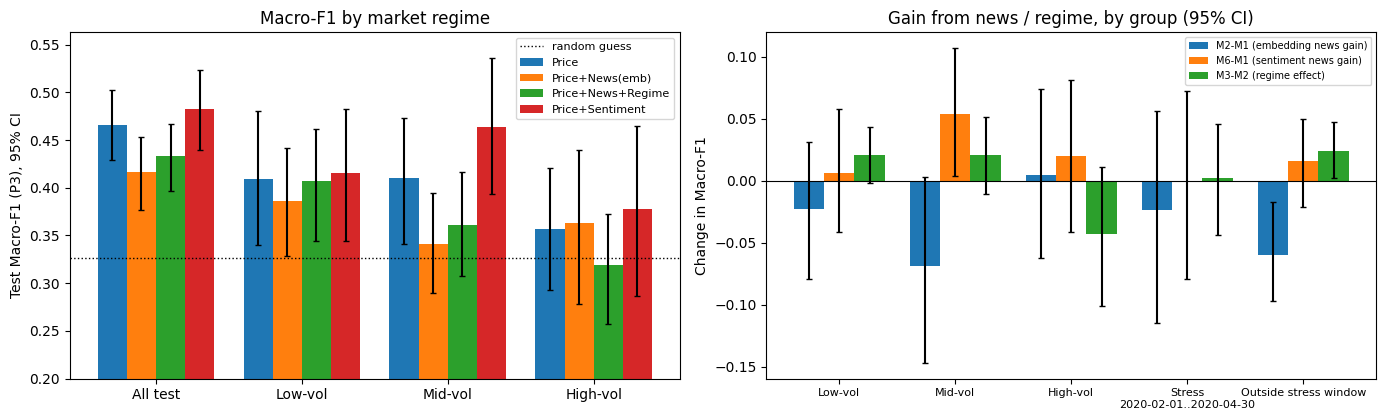

In [19]:

# %% Cell 3: print the result tables (paste these back)
pd.set_option("display.width", 200)
print("Macro-F1 levels with 95% bootstrap CI (P3 test; seed-averaged):")
print(levels.pivot(index="group", columns="model", values="f1").reindex([g for g, _ in groups]).round(3))
print("\nDifferences (positive = second model better), 95% CI from resampling test rows:")
print(diffs.assign(ci=lambda d: "[" + d.lo.astype(str) + ", " + d.hi.astype(str) + "]")[["group", "n", "comparison", "est", "ci"]].to_string(index=False))

# %% Cell 4: figures
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
reg_groups = [g for g, _ in groups if g.startswith("Regime") or g == "All test"]; ms = ["M1", "M2", "M3", "M6"]; w = 0.2
for k, m in enumerate(ms):
    s = levels[levels.model == m].set_index("group").loc[reg_groups]
    ax[0].bar(np.arange(len(reg_groups)) + (k - 1.5) * w, s.f1, w, yerr=[s.f1 - s.lo, s.hi - s.f1], capsize=2, label=NAME[m])
ax[0].axhline(levels[levels.model == "M0r"].f1.mean(), color="k", ls=":", lw=1, label="random guess")
ax[0].set_xticks(range(len(reg_groups))); ax[0].set_xticklabels([g.replace("Regime: ", "") for g in reg_groups]); ax[0].set_ylim(0.2, None)
ax[0].set_ylabel("Test Macro-F1 (P3), 95% CI"); ax[0].set_title("Macro-F1 by market regime"); ax[0].legend(fontsize=8)

dg = [g for g, _ in groups if g != "All test"]; cmp_show = list(COMPS)[:3]; w = 0.26
for k, c in enumerate(cmp_show):
    s = diffs[diffs.comparison == c].set_index("group").loc[dg]
    ax[1].bar(np.arange(len(dg)) + (k - 1) * w, s.est, w, yerr=[s.est - s.lo, s.hi - s.est], capsize=2, label=c)
ax[1].axhline(0, color="k", lw=.8); ax[1].set_xticks(range(len(dg))); ax[1].set_xticklabels([g.replace("Regime: ", "").replace("Stress window ", "Stress\n") for g in dg], fontsize=8)
ax[1].set_ylabel("Change in Macro-F1"); ax[1].set_title("Gain from news / regime, by group (95% CI)"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "fig_regime_news_value.png", dpi=200); plt.show()